In [4]:
# Import libraries for data analysis and spatial visualisation
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import geopandas as gpd

from pathlib import Path

# Load the merged neighbourhood environment and population dataset
spatial_data = pd.read_csv(
    "merged_complete_datasets/berlin_neighbourhood_environment_population.csv"
)

# Inspect dimensions and columns
print("Dataset shape:", spatial_data.shape)

print("\nColumns:")
print(spatial_data.columns.tolist())

# Preview the data
display(spatial_data.head())

Dataset shape: (143, 15)

Columns:
['bzr_id', 'bzr_name', 'bez', 'tree_cover_mean', 'tree_cover_median', 'tree_cover_pixels_pct', 'pixel_count', 'imperviousness_mean', 'green_natural', 'population_2025', 'male_population_2025', 'female_population_2025', 'population_complete', 'area_km2', 'population_density_km2']


,bzr_id,bzr_name,bez,tree_cover_mean,tree_cover_median,tree_cover_pixels_pct,pixel_count,imperviousness_mean,green_natural,population_2025,male_population_2025,female_population_2025,population_complete,area_km2,population_density_km2
0,11001,Tiergarten Süd,01 - Mitte,34.61,0.00,39.34,51720,40.07,48.50,16349.00,8584.00,7765.00,True,5.17,3160.81
1,11002,Regierungsviertel,01 - Mitte,0.75,0.00,1.09,26958,89.48,4.92,13758.00,7056.00,6702.00,True,2.70,5104.11
2,11003,Alexanderplatz,01 - Mitte,3.76,0.00,5.55,62288,74.75,4.91,62409.00,31711.00,30698.00,True,6.23,10019.51
3,11004,Brunnenstraße Süd,01 - Mitte,7.93,0.00,11.10,17548,68.48,16.32,32786.00,16469.00,16317.00,True,1.76,18679.65
4,12005,Moabit West,01 - Mitte,2.91,0.00,4.19,43045,72.33,1.23,47079.00,24689.00,22390.00,True,4.30,10935.94


In [5]:
# Load Berlin Bezirksregion boundaries
lor = gpd.read_file(
    "satellite_data/berlin_lor_2021.geojson"
)

# Inspect the geographical data
print("Shape:", lor.shape)
print("CRS:", lor.crs)
print("\nColumns:")
print(lor.columns.tolist())

display(lor.head())

Shape: (143, 9)
CRS: EPSG:4326

Columns:
['id', 'bzr_id', 'bzr_name', 'pgr_id', 'pgr_name', 'bez', 'finhalt', 'stand', 'geometry']


,id,bzr_id,bzr_name,pgr_id,pgr_name,bez,finhalt,stand,geometry
0,b_lor_bzr_2021.011001,011001,Tiergarten Süd,0110,Zentrum,01 - Mitte,5172480.98,01.12.2021,"MULTIPOLYGON (((13.33601 52.51379, 13.33587 52..."
1,b_lor_bzr_2021.011002,011002,Regierungsviertel,0110,Zentrum,01 - Mitte,2695511.21,01.01.2021,"MULTIPOLYGON (((13.3765 52.51602, 13.37651 52...."
2,b_lor_bzr_2021.011003,011003,Alexanderplatz,0110,Zentrum,01 - Mitte,6228825.14,01.01.2021,"MULTIPOLYGON (((13.37357 52.52788, 13.37364 52..."
3,b_lor_bzr_2021.011004,011004,Brunnenstraße Süd,0110,Zentrum,01 - Mitte,1755196.27,01.01.2021,"MULTIPOLYGON (((13.39586 52.53809, 13.39569 52..."
4,b_lor_bzr_2021.012005,012005,Moabit West,0120,Moabit,01 - Mitte,4305047.09,01.01.2021,"MULTIPOLYGON (((13.33422 52.51677, 13.33431 52..."


In [6]:
# Standardise neighbourhood IDs before merging
spatial_data["bzr_id"] = (
    spatial_data["bzr_id"].astype(str).str.zfill(6)
)

lor["bzr_id"] = (
    lor["bzr_id"].astype(str).str.zfill(6)
)

# Merge environmental and population indicators with geographical boundaries
berlin_map = lor.merge(
    spatial_data,
    on="bzr_id",
    how="left",
    suffixes=("_lor", "")
)

# Check the merge
print("Merged shape:", berlin_map.shape)
print("Missing population density:", 
      berlin_map["population_density_km2"].isna().sum())
print("Unique neighbourhood IDs:", berlin_map["bzr_id"].nunique())

# Check whether every neighbourhood matched
display(
    berlin_map[
        ["bzr_id", "bzr_name", "population_density_km2",
         "imperviousness_mean", "tree_cover_mean"]
    ].head()
)

Merged shape: (143, 23)
Missing population density: 2
Unique neighbourhood IDs: 143


,bzr_id,bzr_name,population_density_km2,imperviousness_mean,tree_cover_mean
0,011001,Tiergarten Süd,3160.81,40.07,34.61
1,011002,Regierungsviertel,5104.11,89.48,0.75
2,011003,Alexanderplatz,10019.51,74.75,3.76
3,011004,Brunnenstraße Süd,18679.65,68.48,7.93
4,012005,Moabit West,10935.94,72.33,2.91


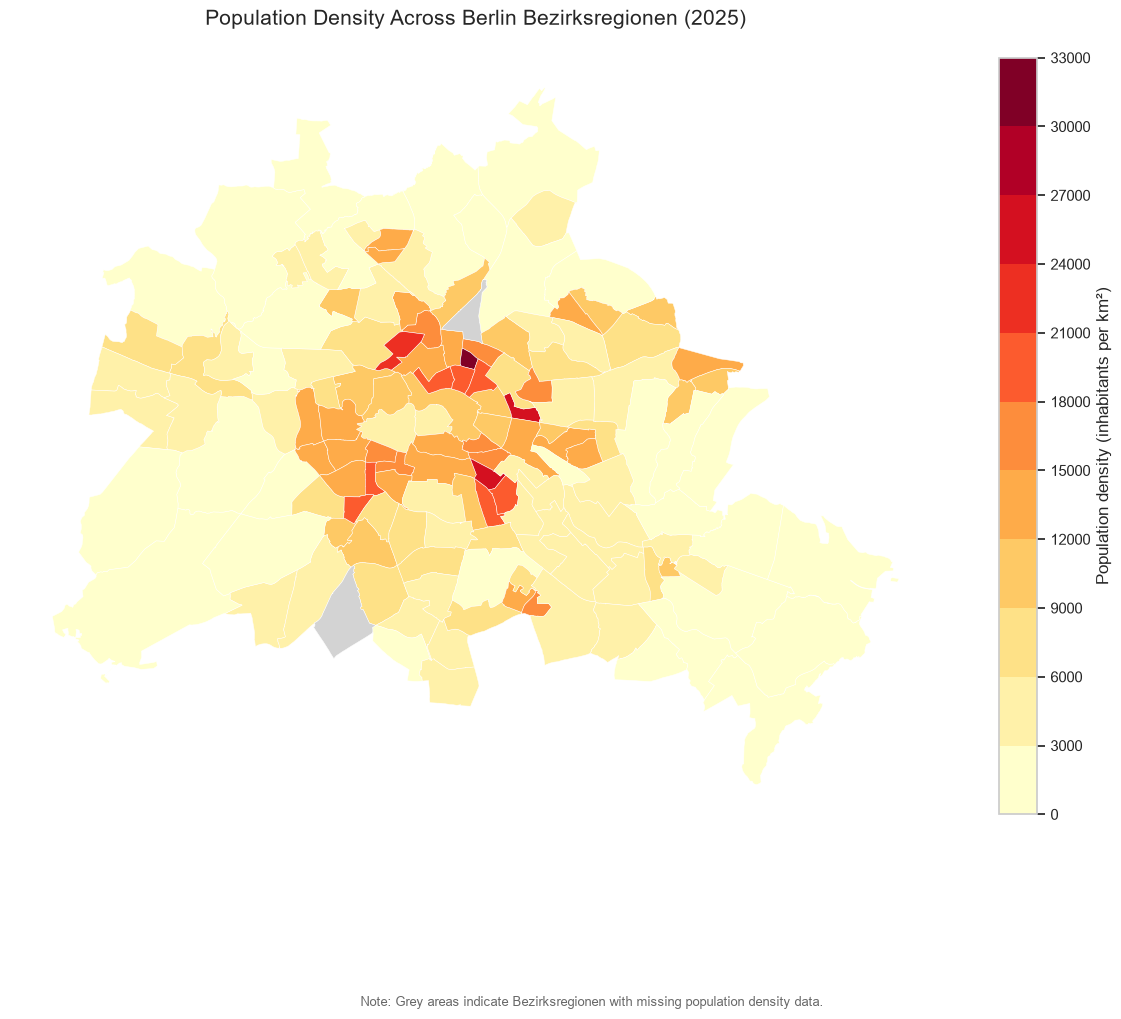

In [9]:
# Define population density intervals in steps of 3,000 inhabitants per km²
max_density = berlin_map["population_density_km2"].max()
upper_bound = int(np.ceil(max_density / 3000) * 3000)

boundaries = np.arange(0, upper_bound + 3000, 3000)

# Create a discrete colour palette and matching intervals
cmap = plt.get_cmap("YlOrRd", len(boundaries) - 1)

from matplotlib.colors import BoundaryNorm
norm = BoundaryNorm(boundaries, cmap.N)

# Create the map
fig, ax = plt.subplots(figsize=(12, 12))

berlin_map.plot(
    column="population_density_km2",
    cmap=cmap,
    norm=norm,
    linewidth=0.35,
    edgecolor="white",
    missing_kwds={
        "color": "lightgrey",
        "label": "Missing population data"
    },
    ax=ax
)

# Add a discrete legend with intervals of 3,000
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

cbar = fig.colorbar(
    sm,
    ax=ax,
    boundaries=boundaries,
    ticks=boundaries,
    shrink=0.65,
    spacing="uniform"
)

cbar.set_label("Population density (inhabitants per km²)")

# Add title and remove axes
ax.set_title(
    "Population Density Across Berlin Bezirksregionen (2025)",
    fontsize=15,
    pad=20
)

ax.set_axis_off()

# Add a note explaining missing data
fig.text(
    0.5, 0.025,
    "Note: Grey areas indicate Bezirksregionen with missing population density data.",
    ha="center",
    fontsize=9,
    color="dimgray"
)

plt.tight_layout()
plt.show()

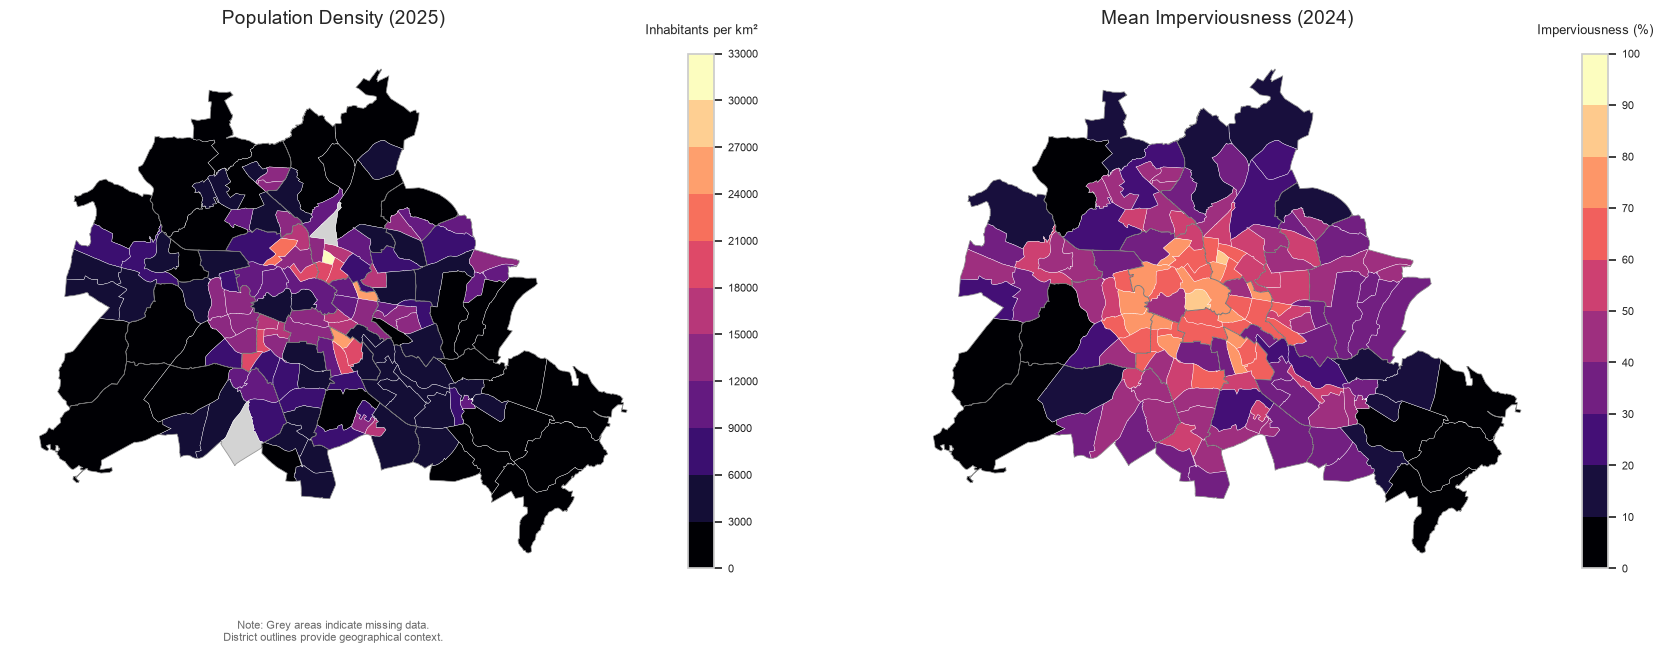

In [14]:
# Define population density intervals in steps of 3,000
density_max = berlin_map["population_density_km2"].max()
density_upper = int(np.ceil(density_max / 3000) * 3000)
density_boundaries = np.arange(0, density_upper + 3000, 3000)

# Define imperviousness intervals in steps of 10 percentage points
impervious_boundaries = np.arange(0, 110, 10)

# Create perceptually uniform colour palettes
density_cmap = plt.get_cmap("magma", len(density_boundaries) - 1)
impervious_cmap = plt.get_cmap("magma", len(impervious_boundaries) - 1)

from matplotlib.colors import BoundaryNorm

density_norm = BoundaryNorm(density_boundaries, density_cmap.N)
impervious_norm = BoundaryNorm(impervious_boundaries, impervious_cmap.N)

# Create district outlines from the LOR boundaries
districts = lor.dissolve(by="bez")

# Create side-by-side maps
fig, axes = plt.subplots(1, 2, figsize=(18, 11))

# Map 1: Population density
berlin_map.plot(
    column="population_density_km2",
    cmap=density_cmap,
    norm=density_norm,
    linewidth=0.25,
    edgecolor="white",
    missing_kwds={"color": "lightgrey"},
    ax=axes[0]
)

# Map 2: Imperviousness
berlin_map.plot(
    column="imperviousness_mean",
    cmap=impervious_cmap,
    norm=impervious_norm,
    linewidth=0.25,
    edgecolor="white",
    missing_kwds={"color": "lightgrey"},
    ax=axes[1]
)

# Add subtle district boundaries to both maps
for ax in axes:
    districts.boundary.plot(
        ax=ax,
        color="dimgray",
        linewidth=0.6,
        alpha=0.65
    )
    ax.set_axis_off()

# Add panel titles
axes[0].set_title(
    "Population Density (2025)",
    fontsize=14,
    pad=15
)

axes[1].set_title(
    "Mean Imperviousness (2024)",
    fontsize=14,
    pad=15
)

# Add separate colourbars
density_sm = plt.cm.ScalarMappable(
    cmap=density_cmap,
    norm=density_norm
)
density_sm.set_array([])

impervious_sm = plt.cm.ScalarMappable(
    cmap=impervious_cmap,
    norm=impervious_norm
)
impervious_sm.set_array([])

density_cbar = fig.colorbar(
    density_sm,
    ax=axes[0],
    boundaries=density_boundaries,
    ticks=density_boundaries,
    shrink=0.65,
    pad=0.04
)

impervious_cbar = fig.colorbar(
    impervious_sm,
    ax=axes[1],
    boundaries=impervious_boundaries,
    ticks=impervious_boundaries,
    shrink=0.65,
    pad=0.04
)

# Add horizontal labels with more spacing
density_cbar.ax.set_title(
    "Inhabitants per km²",
    fontsize=9,
    pad=14
)

impervious_cbar.ax.set_title(
    "Imperviousness (%)",
    fontsize=9,
    pad=14
)

# Improve tick label readability
density_cbar.ax.tick_params(labelsize=8, pad=4)
impervious_cbar.ax.tick_params(labelsize=8, pad=4)

# Add note below the population density map
axes[0].text(
    0.5, -0.08,
    "Note: Grey areas indicate missing data.\nDistrict outlines provide geographical context.",
    transform=axes[0].transAxes,
    ha="center",
    va="top",
    fontsize=8,
    color="dimgray"
)

# Increase space between map titles and colourbar titles
plt.subplots_adjust(
    left=0.03,
    right=0.97,
    top=0.88,
    bottom=0.16,
    wspace=0.12
)

plt.show()

Missing tree-cover values: 0


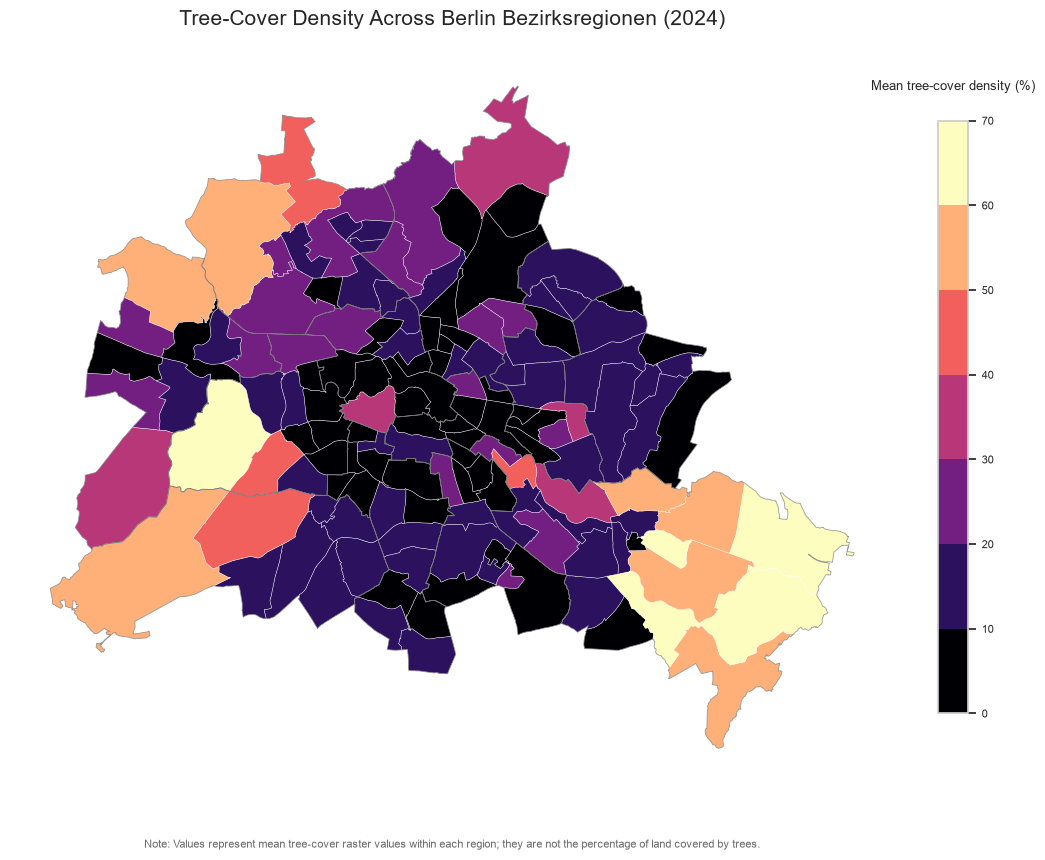

In [16]:
# Check whether tree-cover data contains missing values
tree_missing = berlin_map["tree_cover_mean"].isna().sum()
print(f"Missing tree-cover values: {tree_missing}")

# Define tree-cover intervals in steps of 10 percentage points
tree_max = berlin_map["tree_cover_mean"].max()
tree_upper = int(np.ceil(tree_max / 10) * 10)
tree_boundaries = np.arange(0, tree_upper + 10, 10)

# Create discrete colour palette
tree_cmap = plt.get_cmap("magma", len(tree_boundaries) - 1)

from matplotlib.colors import BoundaryNorm
tree_norm = BoundaryNorm(tree_boundaries, tree_cmap.N)

# Create map
fig, ax = plt.subplots(figsize=(12, 12))

berlin_map.plot(
    column="tree_cover_mean",
    cmap=tree_cmap,
    norm=tree_norm,
    linewidth=0,
    missing_kwds={"color": "lightgrey"},
    ax=ax
)

# Add light, semi-transparent boundaries between Bezirksregionen
berlin_map.boundary.plot(
    ax=ax,
    color="white",
    linewidth=0.35,
    alpha=0.55
)

# Add district boundaries for geographical context
districts.boundary.plot(
    ax=ax,
    color="dimgray",
    linewidth=0.6,
    alpha=0.65
)

# Add colourbar
tree_sm = plt.cm.ScalarMappable(
    cmap=tree_cmap,
    norm=tree_norm
)
tree_sm.set_array([])

tree_cbar = fig.colorbar(
    tree_sm,
    ax=ax,
    boundaries=tree_boundaries,
    ticks=tree_boundaries,
    shrink=0.65,
    pad=0.04
)

tree_cbar.ax.set_title(
    "Mean tree-cover density (%)",
    fontsize=9,
    pad=22
)

tree_cbar.ax.tick_params(labelsize=8, pad=4)

# Add title
ax.set_title(
    "Tree-Cover Density Across Berlin Bezirksregionen (2024)",
    fontsize=15,
    pad=20
)

ax.set_axis_off()

# Add a concise note, adapting it to data completeness
if tree_missing > 0:
    note = (
        "Note: Values represent mean tree-cover raster values within each region. "
        "Grey indicates missing data."
    )
else:
    note = (
        "Note: Values represent mean tree-cover raster values within each region; "
        "they are not the percentage of land covered by trees."
    )

ax.text(
    0.5, -0.08,
    note,
    transform=ax.transAxes,
    ha="center",
    va="top",
    fontsize=8,
    color="dimgray",
    wrap=True
)

# Adjust layout
plt.subplots_adjust(
    left=0.03,
    right=0.94,
    top=0.90,
    bottom=0.14
)

plt.show()

In [17]:
# Select the three variables for spatial correlation analysis
correlation_data = berlin_map[
    [
        "population_density_km2",
        "imperviousness_mean",
        "tree_cover_mean"
    ]
].copy()

# Calculate Spearman correlation coefficients
correlation_matrix = correlation_data.corr(
    method="spearman"
)

# Calculate the number of valid observations for each pair
observation_counts = correlation_data.notna().astype(int).T.dot(
    correlation_data.notna().astype(int)
)

# Display correlation results
print("Spearman correlation matrix:")
display(correlation_matrix.round(3))

print("Number of valid observations per variable pair:")
display(observation_counts)

Spearman correlation matrix:


,population_density_km2,imperviousness_mean,tree_cover_mean
population_density_km2,1.00,0.80,-0.58
imperviousness_mean,0.80,1.00,-0.79
tree_cover_mean,-0.58,-0.79,1.00


Number of valid observations per variable pair:


,population_density_km2,imperviousness_mean,tree_cover_mean
population_density_km2,141,141,141
imperviousness_mean,141,143,143
tree_cover_mean,141,143,143


In [19]:
# Keep only neighbourhoods with complete data for all three variables
correlation_data = berlin_map[
    [
        "population_density_km2",
        "imperviousness_mean",
        "tree_cover_mean"
    ]
].dropna().copy()

# Calculate Spearman correlations using the same observations
correlation_matrix = correlation_data.corr(
    method="spearman"
)

# Confirm the sample size
print("Complete-case sample size:", len(correlation_data))

# Display the updated correlation matrix
display(correlation_matrix.round(2))


Complete-case sample size: 141


,population_density_km2,imperviousness_mean,tree_cover_mean
population_density_km2,1.00,0.80,-0.58
imperviousness_mean,0.80,1.00,-0.79
tree_cover_mean,-0.58,-0.79,1.00


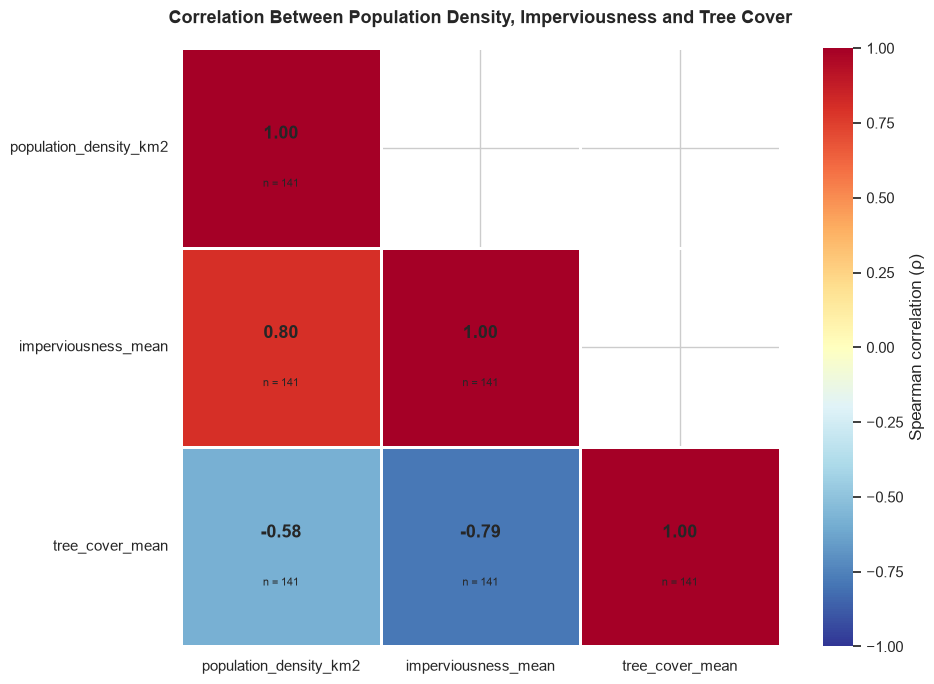

In [20]:

# Create a mask to hide the upper triangle, excluding the diagonal
mask = np.triu(
    np.ones_like(correlation_matrix, dtype=bool),
    k=1
)

# Create the figure
fig, ax = plt.subplots(figsize=(10, 7))

# Draw the triangular correlation heatmap
sns.heatmap(
    correlation_matrix,
    mask=mask,
    annot=False,
    cmap="RdYlBu_r",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=1,
    linecolor="white",
    cbar_kws={"label": "Spearman correlation (ρ)"},
    ax=ax
)

# Add correlation values and sample sizes manually
for row in range(len(correlation_matrix)):
    for col in range(len(correlation_matrix.columns)):
        if not mask[row, col]:
            value = correlation_matrix.iloc[row, col]

            # Bold correlation coefficient
            ax.text(
                col + 0.5,
                row + 0.43,
                f"{value:.2f}",
                ha="center",
                va="center",
                fontsize=13,
                fontweight="bold"
            )

            # Smaller sample size underneath
            ax.text(
                col + 0.5,
                row + 0.68,
                f"n = {len(correlation_data)}",
                ha="center",
                va="center",
                fontsize=8
            )

# Format axis labels
ax.set_xticklabels(
    ax.get_xticklabels(),
    rotation=0,
    ha="center"
)

ax.set_yticklabels(
    ax.get_yticklabels(),
    rotation=0
)

# Add title and improve layout
ax.set_title(
    "Correlation Between Population Density, Imperviousness and Tree Cover",
    fontsize=13,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("")
ax.set_ylabel("")

plt.tight_layout()
plt.show()


- Strong positive relationship (ρ = 0.80): Population density and imperviousness are strongly positively correlated. More densely populated neighbourhoods tend to have a higher share of built-up and sealed surfaces.

- Strong negative relationship (ρ = −0.79): Imperviousness and tree-cover density have a strong inverse relationship. Neighbourhoods with more sealed surfaces tend to have lower average tree-cover values.

- Moderate negative relationship (ρ = −0.58): Population density and tree-cover density are moderately negatively correlated. More densely populated neighbourhoods tend to have lower tree-cover values, although this relationship is less pronounced than the relationship between imperviousness and tree cover.

### Potential heat-exposure screening map.

Identify neighbourhoods where three conditions overlap:
1) High population density: upper 25% (75th percentile).
2) High imperviousness: upper 25%.
3) Low tree cover: lower 25% (25th percentile).

This identifies neighbourhoods that are relatively more exposed to these conditions compared with other Berlin neighbourhoods. The thresholds are relative, not official health or climate-risk thresholds.

In [21]:
# Use the same complete-case dataset as the correlation analysis
exposure_data = berlin_map.loc[
    correlation_data.index
].copy()

# Calculate relative thresholds
density_threshold = exposure_data["population_density_km2"].quantile(0.75)
impervious_threshold = exposure_data["imperviousness_mean"].quantile(0.75)
tree_threshold = exposure_data["tree_cover_mean"].quantile(0.25)

# Identify neighbourhoods meeting each criterion
exposure_data["high_population_density"] = (
    exposure_data["population_density_km2"] >= density_threshold
)

exposure_data["high_imperviousness"] = (
    exposure_data["imperviousness_mean"] >= impervious_threshold
)

exposure_data["low_tree_cover"] = (
    exposure_data["tree_cover_mean"] <= tree_threshold
)

# Combine the three criteria
exposure_data["potential_exposure"] = (
    exposure_data["high_population_density"]
    & exposure_data["high_imperviousness"]
    & exposure_data["low_tree_cover"]
)

# Display thresholds and neighbourhood counts
print("Screening thresholds:")
print(f"High population density: {density_threshold:.0f} people/km²")
print(f"High imperviousness: {impervious_threshold:.2f}%")
print(f"Low tree cover: {tree_threshold:.2f}")

print("\nNeighbourhoods meeting each criterion:")
print("High population density:", exposure_data["high_population_density"].sum())
print("High imperviousness:", exposure_data["high_imperviousness"].sum())
print("Low tree cover:", exposure_data["low_tree_cover"].sum())
print("All three criteria:", exposure_data["potential_exposure"].sum())


Screening thresholds:
High population density: 12273 people/km²
High imperviousness: 60.53%
Low tree cover: 7.16

Neighbourhoods meeting each criterion:
High population density: 36
High imperviousness: 36
Low tree cover: 36
All three criteria: 18


In [ ]:
# Create one geometry for each Berlin district so to add them on the map
district_labels = districts.copy()

# Calculate representative points inside each district
district_labels["label_point"] = (
    district_labels.geometry.representative_point()
)

# Extract coordinates for the labels
district_labels["label_x"] = (
    district_labels["label_point"].x
)

district_labels["label_y"] = (
    district_labels["label_point"].y
)

# Display district names and label coordinates
display(
    district_labels[
        ["label_x", "label_y"]
    ]
)


,label_x,label_y
bez,,
01 - Mitte,13.36,52.53
02 - Friedrichshain-Kreuzberg,13.45,52.51
03 - Pankow,13.44,52.60
04 - Charlottenburg-Wilmersdorf,13.27,52.51
05 - Spandau,13.18,52.52
06 - Steglitz-Zehlendorf,13.24,52.43
07 - Tempelhof-Schöneberg,13.39,52.44
08 - Neukölln,13.44,52.45
09 - Treptow-Köpenick,13.63,52.42


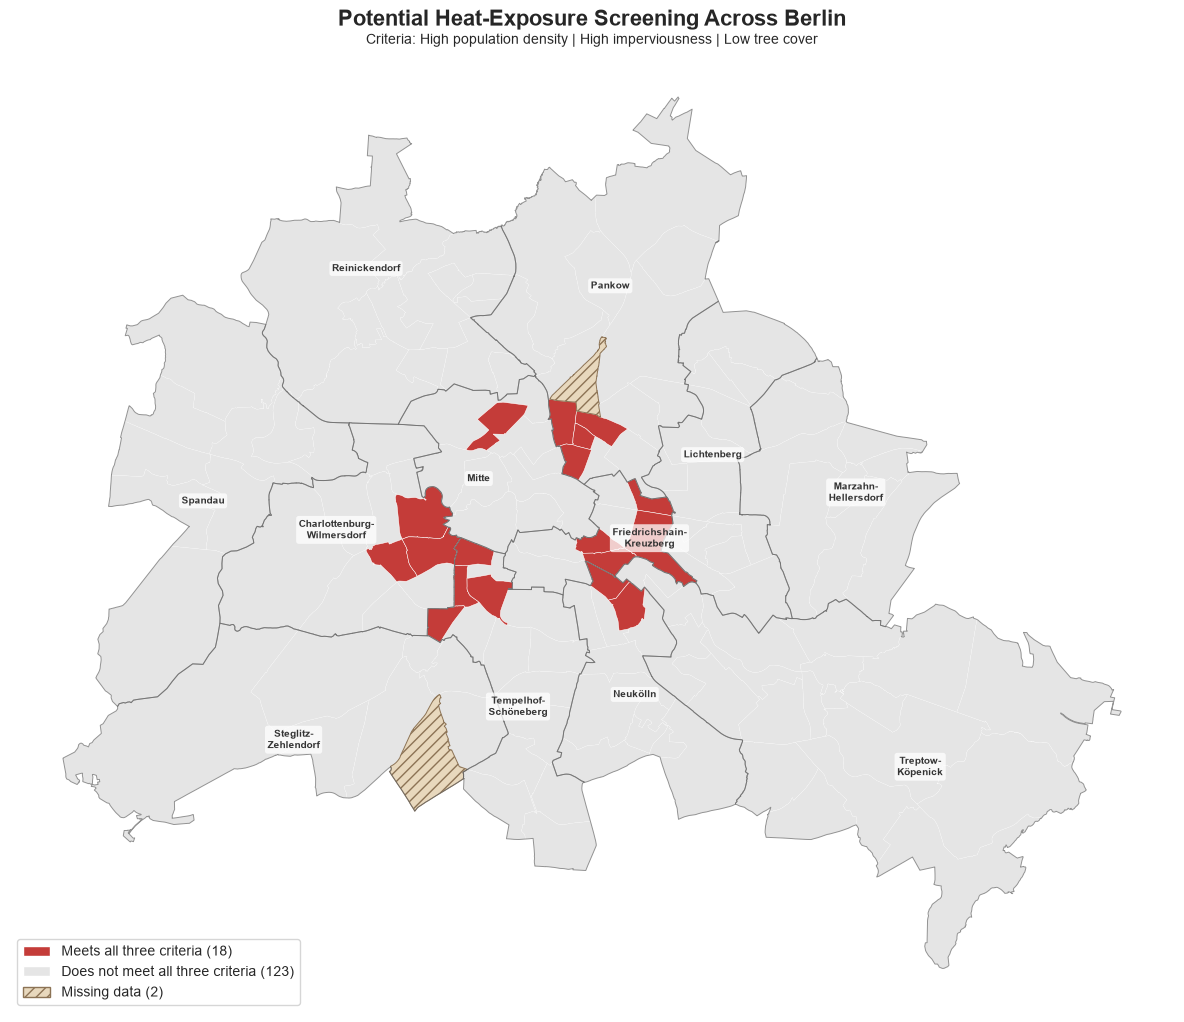

In [26]:

# Add the screening results to the full 143-neighbourhood map
final_map = berlin_map.copy()

final_map["potential_exposure"] = (
    final_map.index.map(
        exposure_data["potential_exposure"]
    )
)

# Define the three map categories
high_exposure = final_map[
    final_map["potential_exposure"] == True
]

other_neighbourhoods = final_map[
    final_map["potential_exposure"] == False
]

missing_neighbourhoods = final_map[
    final_map["potential_exposure"].isna()
]

# Create the figure
fig, ax = plt.subplots(figsize=(12, 11))

# Plot neighbourhoods that do not meet all three criteria
other_neighbourhoods.plot(
    ax=ax,
    color="#e5e5e5",
    edgecolor="white",
    linewidth=0.15
)

# Highlight neighbourhoods meeting all three criteria
high_exposure.plot(
    ax=ax,
    color="#c43c39",
    edgecolor="white",
    linewidth=0.35
)

# Highlight neighbourhoods with missing data
missing_neighbourhoods.plot(
    ax=ax,
    color="#e8d8bd",
    edgecolor="#8c7355",
    linewidth=0.7,
    hatch="///"
)

# Add district boundaries
districts.boundary.plot(
    ax=ax,
    color="dimgray",
    linewidth=0.7,
    alpha=0.7
)

# Add title and explicit screening criteria
ax.set_title(
    "Potential Heat-Exposure Screening Across Berlin",
    fontsize=16,
    fontweight="bold",
    pad=20
)

ax.text(
    0.5,
    1.01,
    "Criteria: High population density | High imperviousness | Low tree cover",
    transform=ax.transAxes,
    ha="center",
    fontsize=10
)


# Define small manual offsets to separate nearby district labels
label_offsets = {
    "01 - Mitte": (-8, -10),
    "02 - Friedrichshain-Kreuzberg": (12, -4),
    "03 - Pankow": (0, 9),
    "04 - Charlottenburg-Wilmersdorf": (-12, 0),
    "05 - Spandau": (-5, 0),
    "06 - Steglitz-Zehlendorf": (-8, -5),
    "07 - Tempelhof-Schöneberg": (-12, -2),
    "08 - Neukölln": (10, -3),
    "09 - Treptow-Köpenick": (8, -3),
    "10 - Marzahn-Hellersdorf": (8, 0),
    "11 - Lichtenberg": (12, 9),
    "12 - Reinickendorf": (-8, 8)
}

# Add district names using representative points
for district, row in district_labels.iterrows():

    # Extract the district name without its numerical code
    label = district.split(" - ", 1)[1]

    # Add line breaks to longer names
    label = label.replace("-", "-\n")

    # Get the manual label offset
    offset = label_offsets[district]

    # Place the label on the map
    ax.annotate(
        label,
        xy=(row["label_x"], row["label_y"]),
        xytext=offset,
        textcoords="offset points",
        ha="center",
        va="center",
        fontsize=7.5,
        fontweight="bold",
        color="#333333",
        bbox={
            "boxstyle": "round,pad=0.25",
            "facecolor": "white",
            "edgecolor": "none",
            "alpha": 0.75
        },
        zorder=10
    )

# Create a custom legend
from matplotlib.patches import Patch

legend_elements = [
    Patch(
        facecolor="#c43c39",
        edgecolor="white",
        label="Meets all three criteria (18)"
    ),
    Patch(
        facecolor="#e5e5e5",
        edgecolor="white",
        label="Does not meet all three criteria (123)"
    ),
    Patch(
        facecolor="#e8d8bd",
        edgecolor="#8c7355",
        hatch="///",
        label="Missing data (2)"
    )
]

ax.legend(
    handles=legend_elements,
    loc="lower left",
    frameon=True,
    fontsize=10
)

ax.set_axis_off()

plt.tight_layout()
plt.show()


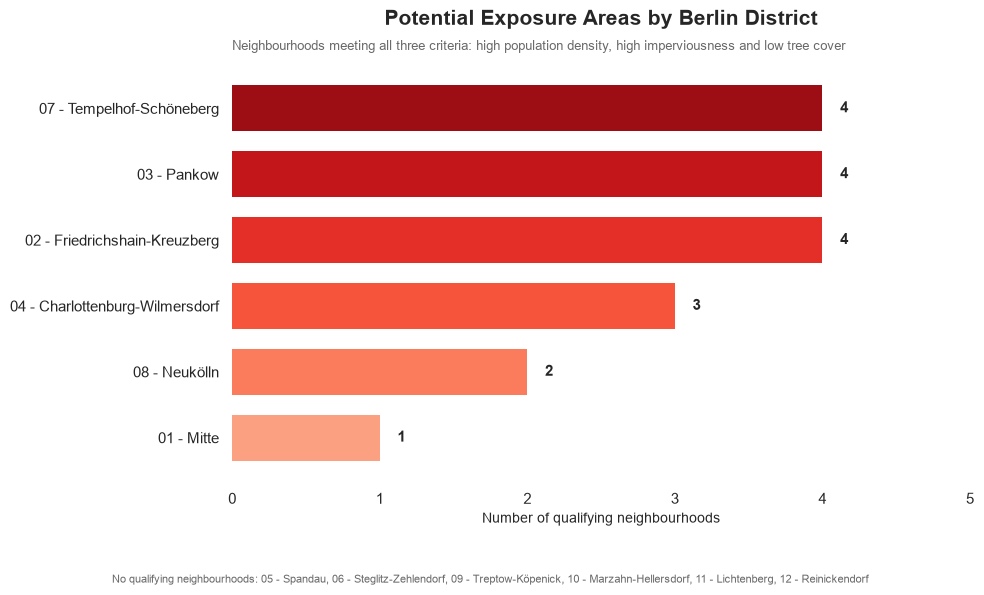

In [28]:
# Keep only districts with at least one qualifying neighbourhood
district_counts = (
    exposure_data.groupby("bez")["potential_exposure"]
    .sum()
    .loc[lambda x: x > 0]
    .sort_values(ascending=True)
)

# Create a sequential colour gradient based on the counts
bar_colors = sns.color_palette(
    "Reds",
    n_colors=len(district_counts) + 2
)[2:]

# Create the figure
fig, ax = plt.subplots(figsize=(10, 6))

# Draw horizontal bars
bars = ax.barh(
    district_counts.index,
    district_counts.values,
    color=bar_colors,
    edgecolor="none",
    height=0.7
)

# Add values at the end of each bar
for bar in bars:
    width = bar.get_width()

    ax.text(
        width + 0.12,
        bar.get_y() + bar.get_height() / 2,
        f"{int(width)}",
        va="center",
        fontsize=11,
        fontweight="bold"
    )

# Add title and subtitle
ax.set_title(
    "Potential Exposure Areas by Berlin District",
    fontsize=15,
    fontweight="bold",
    pad=30
)

ax.text(
    0,
    1.04,
    "Neighbourhoods meeting all three criteria: high population density, "
    "high imperviousness and low tree cover",
    transform=ax.transAxes,
    fontsize=9,
    color="dimgray"
)

# Format axes
ax.set_xlabel("Number of qualifying neighbourhoods", fontsize=10)
ax.set_ylabel("")
ax.set_xlim(0, district_counts.max() + 1)

# Remove gridlines for a cleaner presentation
ax.grid(False)
sns.despine(left=True, bottom=True)

# Add note listing districts with zero qualifying neighbourhoods
zero_districts = (
    exposure_data.groupby("bez")["potential_exposure"]
    .sum()
    .loc[lambda x: x == 0]
    .index
)

zero_note = (
    "No qualifying neighbourhoods: "
    + ", ".join(zero_districts)
)

fig.text(
    0.12,
    0.015,
    zero_note,
    fontsize=8,
    color="dimgray",
    wrap=True
)

plt.tight_layout(rect=[0, 0.08, 1, 1])
plt.show()


Eighteen neighbourhoods across six Berlin districts meet all three relative screening criteria. Pankow, Friedrichshain-Kreuzberg and Tempelhof-Schöneberg have the highest counts, with four qualifying neighbourhoods each.